# Практична 07. GPU і CUDA: множина Мандельброта в Colab

Студент: Герасимов Володимир Володимирович, група 416-пр. Задача та сама, що всі тижні семестру:
Мандельброт, `max_iter = 300`, область x∈[−2,2; 0,8], y∈[−1,0; 1,0], крок сітки `(X_MAX − X_MIN)/(W − 1)`
(як у `1-poslidovno/mandelbrot.py`). Ядро й еталон написані за моїм кодом із практичних 02 і 06.

⚠️ **Умови:** замір на машині Colab (карта й процесор Colab друкуються нижче), не на моєму ноутбуці. Прогонів 5, результат: мінімум.
Що входить у час: окремо «туди» (host → карта), «ядро» (з `cuda.synchronize()`), «назад» (карта → host).
Декларація щодо ШІ:текст зошита підготовлено з допомогою Claude Code (Anthropic)

## Крок 0. Середовище

In [1]:
!nvidia-smi
!lscpu | grep -E "Model name|^CPU\(s\)"

Mon Oct 19 13:55:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import time, os
import numba, numpy as np
from numba import cuda

print("numba", numba.__version__, "| numpy", np.__version__)
print("cuda.is_available:", cuda.is_available())
dev = cuda.get_current_device()
KARTA = dev.name.decode() if isinstance(dev.name, bytes) else dev.name
print("карта:", KARTA)
print("мультипроцесорів (SM):", dev.MULTIPROCESSOR_COUNT, "| розмір варпу:", dev.WARP_SIZE)
print("логічних ядер процесора Colab:", os.cpu_count())
SM = dev.MULTIPROCESSOR_COUNT

numba 0.61.2 | numpy 2.1.3
cuda.is_available: True
карта: Tesla T4
мультипроцесорів (SM): 40 | розмір варпу: 32
логічних ядер процесора Colab: 2


## Крок 1. Ядро

Кожен потік рахує **одну точку**. Обидва зовнішні цикли з практичної 06 зникли: їх замінила сітка потоків.
Перший рядок ядра це перевірка меж: блоки фіксованого розміру, тож потоків буває більше, ніж точок.

In [3]:
MAX_ITER = 300
X_MIN, X_MAX = -2.2, 0.8
Y_MIN, Y_MAX = -1.0, 1.0


def krok(W, H):
    # той самий крок, що в ядрі з тижня 2: ширина / (W - 1)
    return (X_MAX - X_MIN) / (W - 1), (Y_MAX - Y_MIN) / (H - 1)


@cuda.jit
def mandelbrot_gpu(out, x_min, dx, y_min, dy, max_iter):
    x, y = cuda.grid(2)                                  # хто я в сітці
    if x >= out.shape[1] or y >= out.shape[0]:           # потік без точки не пише за межі масиву
        return
    cx = x_min + x * dx
    cy = y_min + y * dy
    zx = 0.0
    zy = 0.0
    n = 0
    while n < max_iter and zx * zx + zy * zy <= 4.0:     # той самий внутрішній цикл
        zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
        n += 1
    out[y, x] = n


def blokiv_dlya(W, H, blok=(16, 16)):
    # округлення вгору: блоків має вистачити на ВСІ точки
    return ((W + blok[0] - 1) // blok[0], (H + blok[1] - 1) // blok[1])


def rozihriv(sekund=1.0, W=1200, H=800):
    # T4 після простою стоїть на низьких частотах (в nvidia-smi стан P8) і розганяється лише під навантаженням:
    # у першому запуску без прогріву те саме ядро 1200x800 давало 17.65 мс, а за хвилину 6.4 мс.
    # Крутимо ядро ~секунду, щоб міряти стале значення, а не розгін.
    dx, dy = krok(W, H)
    d = cuda.device_array((H, W), dtype=np.int32)
    t0 = time.perf_counter()
    while time.perf_counter() - t0 < sekund:
        mandelbrot_gpu[blokiv_dlya(W, H), (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
        cuda.synchronize()


# перевірка формули блоків: 1200x800 -> 75x50, 1000x700 -> 63x44
assert blokiv_dlya(1200, 800) == (75, 50), blokiv_dlya(1200, 800)
assert blokiv_dlya(1000, 700) == (63, 44), blokiv_dlya(1000, 700)
print("формула блоків правильна: 1200x800 ->", blokiv_dlya(1200, 800), "; 1000x700 ->", blokiv_dlya(1000, 700))

формула блоків правильна: 1200x800 -> (75, 50) ; 1000x700 -> (63, 44)


блоків: (75, 50) = 3750 | потоків усього: 960000 | точок: 960000
мінімум і максимум у результаті: 1 300 (очікуємо від 1 до 300 )


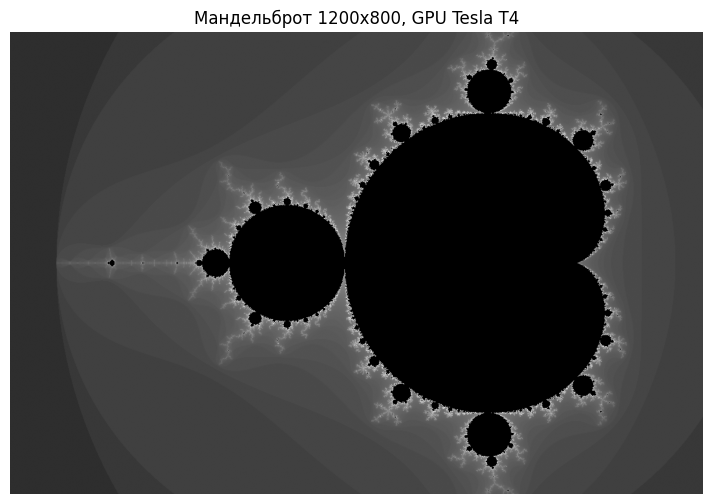

In [4]:
import matplotlib.pyplot as plt

W, H = 1200, 800
dx, dy = krok(W, H)
potokiv = (16, 16)
blokiv = blokiv_dlya(W, H, potokiv)
print("блоків:", blokiv, "=", blokiv[0] * blokiv[1], "| потоків усього:", blokiv[0] * blokiv[1] * 256, "| точок:", W * H)

d_out = cuda.device_array((H, W), dtype=np.int32)
mandelbrot_gpu[blokiv, potokiv](d_out, X_MIN, dx, Y_MIN, dy, MAX_ITER)
out = d_out.copy_to_host()
print("мінімум і максимум у результаті:", out.min(), out.max(), "(очікуємо від 1 до", MAX_ITER, ")")

GAMMA = np.array([0 if n == MAX_ITER else int(255 * (n / MAX_ITER) ** 0.3) for n in range(MAX_ITER + 1)], dtype=np.uint8)
plt.figure(figsize=(9, 6))
plt.imshow(GAMMA[out], cmap="gray")
plt.title(f"Мандельброт {W}x{H}, GPU {KARTA}")
plt.axis("off")
plt.show()

## Крок 2. Еталон у тому самому зошиті

Порівнювати треба з тим, що порахувала **ця сама машина**: моя функція `@njit(parallel=True)` із практичної 06,
запущена на процесорі Colab з тими самими межами. Різниця в останньому біті не змішується з різницею заліза.

In [5]:
from numba import njit, prange


@njit(parallel=True)
def mandelbrot_prange(W, H, MAX_ITER, X_MIN, DX, Y_MIN, DY):
    out = np.empty((H, W), dtype=np.int32)
    for j in prange(H):
        cy = Y_MIN + j * DY
        for i in range(W):
            cx = X_MIN + i * DX
            x = 0.0
            y = 0.0
            n = 0
            while n < MAX_ITER and x * x + y * y <= 4.0:
                x, y = x * x - y * y + cx, 2.0 * x * y + cy
                n += 1
            out[j, i] = n
    return out


def chas_cpu(W, H, n=5):
    dx, dy = krok(W, H)
    best = float("inf")
    for _ in range(n):
        t0 = time.perf_counter()
        r = mandelbrot_prange(W, H, MAX_ITER, X_MIN, dx, Y_MIN, dy)
        best = min(best, time.perf_counter() - t0)
    return best, r


t0 = time.perf_counter()
mandelbrot_prange(W, H, MAX_ITER, X_MIN, dx, Y_MIN, dy)            # перший виклик = компіляція (в замір не входить)
print(f"компіляція + перший виклик prange на процесорі Colab: {time.perf_counter() - t0:.2f} с")
T_CPU, ref = chas_cpu(W, H)
print(f"еталон: njit(parallel=True) на процесорі Colab, {W}x{H}: {T_CPU * 1000:.1f} мс (мінімум із 5)")

rozbizhnyh = int((out != ref).sum())
print("розбіжних точок:", rozbizhnyh, "з", W * H)

компіляція + перший виклик prange на процесорі Colab: 1.73 с
еталон: njit(parallel=True) на процесорі Colab, 1200x800: 183.0 мс (мінімум із 5)
розбіжних точок: 2 з 960000


## Крок 3. Три числа: туди, ядро, назад

⚠️ Запуск ядра **не чекає** його завершення. Без `cuda.synchronize()` міряється лише час запуску.
**Прогрів карти.** Перший запуск цього зошита (без прогріву) показав, що те саме ядро 1200×800 коштує 17,65 мс на початку сеансу, 8,5 мс
через кілька хвилин і 6,4 мс ще пізніше: T4 після простою стоїть на низьких частотах і розганяється під навантаженням. Тому перед
кожним заміром викликається `rozihriv()` (карта ~секунду рахує), і міряється вже стале значення. Сирий вивід першого запуску:
`5-gpu/zapusk1_kholodnyi_start.txt`.

`cuda.synchronize()` ставлю перед кожним показом секундоміра: перед початком (щоб не захопити хвіст попередньої роботи),
після `to_device` (копіювання теж асинхронне) і після ядра. Після `copy_to_host()` синхронізація не потрібна: це блокуюча операція,
вона повертає керування лише тоді, коли дані вже на хості.

In [6]:
def zamir_gpu(W, H, blok=(16, 16), n=5):
    dx, dy = krok(W, H)
    host = np.empty((H, W), np.int32)
    blokiv = blokiv_dlya(W, H, blok)
    # прогрів: перший запуск довший (компіляція ядра під цю карту й тип аргументів), у замір не входить
    d = cuda.to_device(host)
    mandelbrot_gpu[blokiv, blok](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
    cuda.synchronize()
    rozihriv(1.0)                                      # розігнати карту (див. rozihriv)
    ryadky = []
    for _ in range(n):
        cuda.synchronize()
        t0 = time.perf_counter()
        d = cuda.to_device(host)                       # 1) host -> карта
        cuda.synchronize()
        t1 = time.perf_counter()
        mandelbrot_gpu[blokiv, blok](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)   # 2) ядро
        cuda.synchronize()
        t2 = time.perf_counter()
        res = d.copy_to_host()                         # 3) карта -> host (блокує)
        t3 = time.perf_counter()
        ryadky.append((t1 - t0, t2 - t1, t3 - t2, res))
    best = min(ryadky, key=lambda r: r[0] + r[1] + r[2])      # найкращий прогін за сумою
    return best + (ryadky,)


t_tudy, t_yadro, t_nazad, res, vsi = zamir_gpu(W, H)
razom = t_tudy + t_yadro + t_nazad
print(f"{W}x{H}: туди {t_tudy * 1000:.3f} мс | ядро {t_yadro * 1000:.3f} мс | назад {t_nazad * 1000:.3f} мс | разом {razom * 1000:.3f} мс")
print(f"частка копіювання: {(t_tudy + t_nazad) / razom * 100:.1f} %")
print("усі прогони (туди, ядро, назад, мс):")
for a, b, c, _ in vsi:
    print(f"   {a * 1000:.3f}  {b * 1000:.3f}  {c * 1000:.3f}")
print("розбіжних точок з еталоном:", int((res != ref).sum()))
print(f"ядро проти njit(parallel=True) на CPU Colab: ×{T_CPU / t_yadro:.1f} (лише ядро), ×{T_CPU / razom:.1f} (з копіюванням)")

1200x800: туди 1.378 мс | ядро 6.488 мс | назад 2.649 мс | разом 10.515 мс
частка копіювання: 38.3 %
усі прогони (туди, ядро, назад, мс):
   1.459  6.460  2.627
   1.378  6.488  2.649
   1.191  6.516  3.126
   1.550  6.512  3.016
   1.419  6.405  2.869
розбіжних точок з еталоном: 2
ядро проти njit(parallel=True) на CPU Colab: ×28.2 (лише ядро), ×17.4 (з копіюванням)


### Пастка: ядро без `synchronize` і з ним

In [7]:
blokiv = blokiv_dlya(W, H)
d = cuda.device_array((H, W), dtype=np.int32)
mandelbrot_gpu[blokiv, (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
cuda.synchronize()
rozihriv(1.0)
bez, z = [], []
for _ in range(5):
    cuda.synchronize()
    t0 = time.perf_counter()
    mandelbrot_gpu[blokiv, (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
    bez.append(time.perf_counter() - t0)                       # керування повернулось одразу
    cuda.synchronize()                                         # дочекатись, щоб не накладались запуски
for _ in range(5):
    cuda.synchronize()
    t0 = time.perf_counter()
    mandelbrot_gpu[blokiv, (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
    cuda.synchronize()
    z.append(time.perf_counter() - t0)
print(f"БЕЗ synchronize: {min(bez) * 1000:.4f} мс (це час постановки в чергу, а не обчислення)")
print(f"З synchronize:   {min(z) * 1000:.4f} мс")
print(f"«прискорення» без synchronize: ×{min(z) / min(bez):.0f} (брехня: GPU не став швидшим, просто секундомір зупинили до кінця роботи)")
print(f"«прискорення» проти CPU, якби міряв без synchronize: ×{T_CPU / min(bez):.0f}")

БЕЗ synchronize: 0.0661 мс (це час постановки в чергу, а не обчислення)
З synchronize:   6.4145 мс
«прискорення» без synchronize: ×97 (брехня: GPU не став швидшим, просто секундомір зупинили до кінця роботи)
«прискорення» проти CPU, якби міряв без synchronize: ×2768


## Крок 4. Три розміри задачі

In [8]:
rozmiry = [(300, 200), (1200, 800), (3000, 2000)]
ryadky = []
zbirka = {}
for (w, h) in rozmiry:
    a, b, c, r, _ = zamir_gpu(w, h)
    ryadky.append((w, h, a, b, c))
    zbirka[(w, h)] = (a, b, c)
print("| розмір | туди, мс | ядро, мс | назад, мс | разом, мс | частка копіювання |")
print("|---|---|---|---|---|---|")
for w, h, a, b, c in ryadky:
    tot = a + b + c
    print(f"| {w}x{h} | {a * 1000:.3f} | {b * 1000:.3f} | {c * 1000:.3f} | {tot * 1000:.3f} | {(a + c) / tot * 100:.1f} % |")

| розмір | туди, мс | ядро, мс | назад, мс | разом, мс | частка копіювання |
|---|---|---|---|---|---|
| 300x200 | 0.287 | 0.981 | 0.128 | 1.396 | 29.7 % |
| 1200x800 | 1.223 | 6.470 | 2.690 | 10.383 | 37.7 % |
| 3000x2000 | 5.269 | 37.124 | 8.806 | 51.199 | 27.5 % |


## ⭐4. Де перетин: GPU проти `njit(parallel=True)` на **тій самій** машині (Colab)

Обидві криві зняті в цьому зошиті, тож порівняння чесне (не ноутбук проти хмари).

In [9]:
rozmiry4 = [(100, 60), (300, 200), (600, 400), (1200, 800), (2400, 1600), (3000, 2000)]
print("| розмір | CPU njit(parallel), мс | GPU лише ядро, мс | GPU з копіюванням, мс | CPU / GPU(ядро) | CPU / GPU(з копіюванням) |")
print("|---|---|---|---|---|---|")
for (w, h) in rozmiry4:
    t_cpu, _ = chas_cpu(w, h, n=20 if w * h < 100000 else 5)
    a, b, c, _, _ = zamir_gpu(w, h, n=20 if w * h < 100000 else 5)
    tot = a + b + c
    print(f"| {w}x{h} | {t_cpu * 1000:.3f} | {b * 1000:.3f} | {tot * 1000:.3f} | ×{t_cpu / b:.2f} | ×{t_cpu / tot:.2f} |")

| розмір | CPU njit(parallel), мс | GPU лише ядро, мс | GPU з копіюванням, мс | CPU / GPU(ядро) | CPU / GPU(з копіюванням) |
|---|---|---|---|---|---|


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 28 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


| 100x60 | 1.087 | 0.327 | 0.598 | ×3.33 | ×1.82 |
| 300x200 | 10.761 | 0.971 | 1.343 | ×11.08 | ×8.01 |
| 600x400 | 44.218 | 1.959 | 2.934 | ×22.57 | ×15.07 |
| 1200x800 | 180.659 | 6.480 | 8.669 | ×27.88 | ×20.84 |
| 2400x1600 | 731.313 | 24.181 | 31.374 | ×30.24 | ×23.31 |
| 3000x2000 | 1150.546 | 37.446 | 51.890 | ×30.73 | ×22.17 |


## ⭐1. Розмір блока

Результат скрізь однаковий, а час? 10×10 це 100 потоків, тобто 3,125 варпу: в останньому варпі 28 із 32 потоків (87,5 %) нічого корисного не роблять
(100 потоків у 4 варпах = 128 місць, з них 28 порожні).

In [10]:
def t_yadro(blok, n=7, W=1200, H=800, kernel=None):
    kernel = kernel or mandelbrot_gpu
    dx, dy = krok(W, H)
    blokiv = blokiv_dlya(W, H, blok)
    d = cuda.device_array((H, W), dtype=np.int32)
    kernel[blokiv, blok](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
    cuda.synchronize()
    rozihriv(0.5)
    best = float("inf")
    for _ in range(n):
        cuda.synchronize()
        t0 = time.perf_counter()
        kernel[blokiv, blok](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
        cuda.synchronize()
        best = min(best, time.perf_counter() - t0)
    return best, d.copy_to_host()


print("| блок | потоків у блоці | варпів | ядро, мс | розбіжних точок з еталоном |")
print("|---|---|---|---|---|")
for blok in [(8, 8), (16, 16), (32, 32), (10, 10)]:
    t, r = t_yadro(blok)
    p = blok[0] * blok[1]
    print(f"| {blok[0]}x{blok[1]} | {p} | {p / 32:.3f} | {t * 1000:.3f} | {int((r != ref).sum())} |")

| блок | потоків у блоці | варпів | ядро, мс | розбіжних точок з еталоном |
|---|---|---|---|---|
| 8x8 | 64 | 2.000 | 6.194 | 2 |
| 16x16 | 256 | 8.000 | 6.377 | 2 |
| 32x32 | 1024 | 32.000 | 7.088 | 2 |
| 10x10 | 100 | 3.125 | 7.786 | 2 |


## ⭐2. `float32` замість `float64`

T4 це карта для інференсу: подвійна точність на ній виконується приблизно у 32 рази повільніше за одинарну.

In [11]:
f32 = np.float32


@cuda.jit
def mandelbrot_f32(out, x_min, dx, y_min, dy, max_iter):
    x, y = cuda.grid(2)
    if x >= out.shape[1] or y >= out.shape[0]:
        return
    cx = x_min + f32(x) * dx
    cy = y_min + f32(y) * dy
    zx = f32(0.0)
    zy = f32(0.0)
    n = 0
    while n < max_iter and zx * zx + zy * zy <= f32(4.0):
        zx, zy = zx * zx - zy * zy + cx, f32(2.0) * zx * zy + cy
        n += 1
    out[y, x] = n


dx, dy = krok(W, H)
blokiv = blokiv_dlya(W, H)
d32 = cuda.device_array((H, W), dtype=np.int32)
args32 = (f32(X_MIN), f32(dx), f32(Y_MIN), f32(dy), MAX_ITER)
mandelbrot_f32[blokiv, (16, 16)](d32, *args32)
cuda.synchronize()
rozihriv(0.5)
best32 = float("inf")
for _ in range(7):
    cuda.synchronize()
    t0 = time.perf_counter()
    mandelbrot_f32[blokiv, (16, 16)](d32, *args32)
    cuda.synchronize()
    best32 = min(best32, time.perf_counter() - t0)
r32 = d32.copy_to_host()
t64, _ = t_yadro((16, 16))
rozb32 = int((r32 != ref).sum())
print(f"float64: {t64 * 1000:.3f} мс | float32: {best32 * 1000:.3f} мс | float32 швидший у ×{t64 / best32:.1f}")
print(f"розбіжних точок float32 з еталоном: {rozb32} з {W * H} ({rozb32 / (W * H) * 100:.3f} %)")

float64: 6.333 мс | float32: 0.229 мс | float32 швидший у ×27.7
розбіжних точок float32 з еталоном: 2803 з 960000 (0.292 %)


## ⭐3. Чи впираємось у шину

Масив 1200×800 з `int32` це 3,66 МіБ. Ділимо його на час копіювання; теоретично PCIe 3.0 ×16 дає ~15,75 ГБ/с в один бік.

In [12]:
nbytes = H * W * 4
host = np.empty((H, W), np.int32)
pinned = cuda.pinned_array((H, W), dtype=np.int32)


def t_kopiya(arr, n=20):
    tt, tn = float("inf"), float("inf")
    for _ in range(n):
        cuda.synchronize()
        t0 = time.perf_counter()
        d = cuda.to_device(arr)
        cuda.synchronize()
        tt = min(tt, time.perf_counter() - t0)
        t0 = time.perf_counter()
        d.copy_to_host(arr)
        tn = min(tn, time.perf_counter() - t0)
    return tt, tn


for nazva, arr in (("звичайна пам'ять", host), ("закріплена (pinned) пам'ять", pinned)):
    tt, tn = t_kopiya(arr)
    print(f"{nazva}: туди {tt * 1000:.3f} мс ({nbytes / tt / 1e9:.2f} ГБ/с), назад {tn * 1000:.3f} мс ({nbytes / tn / 1e9:.2f} ГБ/с)")
print(f"розмір масиву: {nbytes / 2**20:.2f} МіБ; теоретична межа PCIe 3.0 x16: 15.75 ГБ/с в один бік")

звичайна пам'ять: туди 1.206 мс (3.19 ГБ/с), назад 0.629 мс (6.10 ГБ/с)
закріплена (pinned) пам'ять: туди 0.661 мс (5.81 ГБ/с), назад 0.340 мс (11.29 ГБ/с)
розмір масиву: 3.66 МіБ; теоретична межа PCIe 3.0 x16: 15.75 ГБ/с в один бік


## Крок 7. Потоків менше, ніж точок: цикл із кроком сітки (grid-stride loop)

Сітка фіксованого розміру, яка не залежить від W і H: блоки 16×16, блоків `(SM × k, 4)`.
Кожен потік починає з точки `(cuda.grid(2))` і йде по рядках і стовпцях з кроком `cuda.gridsize(2)`.

In [13]:
@cuda.jit
def mandelbrot_stride(out, x_min, dx, y_min, dy, max_iter):
    start_x, start_y = cuda.grid(2)
    krok_x, krok_y = cuda.gridsize(2)                    # скільки потоків у всій сітці по x і по y
    for y in range(start_y, out.shape[0], krok_y):
        cy = y_min + y * dy
        for x in range(start_x, out.shape[1], krok_x):
            cx = x_min + x * dx
            zx = 0.0
            zy = 0.0
            n = 0
            while n < max_iter and zx * zx + zy * zy <= 4.0:
                zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
                n += 1
            out[y, x] = n


dx, dy = krok(W, H)
d = cuda.device_array((H, W), dtype=np.int32)
print("| k | блоків | потоків усього | точок на потік (середнє) | ядро, мс | розбіжних точок |")
print("|---|---|---|---|---|---|")
t_stride = {}
for k in (1, 2, 4, 8, 16):
    blokiv_s = (SM * k, 4)
    potokiv_vsogo = blokiv_s[0] * blokiv_s[1] * 256
    mandelbrot_stride[blokiv_s, (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
    cuda.synchronize()
    rozihriv(0.5)
    best = float("inf")
    for _ in range(7):
        cuda.synchronize()
        t0 = time.perf_counter()
        mandelbrot_stride[blokiv_s, (16, 16)](d, X_MIN, dx, Y_MIN, dy, MAX_ITER)
        cuda.synchronize()
        best = min(best, time.perf_counter() - t0)
    r = d.copy_to_host()
    t_stride[k] = best
    print(f"| {k} | {blokiv_s[0]}x{blokiv_s[1]} = {blokiv_s[0] * blokiv_s[1]} | {potokiv_vsogo} | {W * H / potokiv_vsogo:.1f} | "
          f"{best * 1000:.3f} | {int((r != ref).sum())} |")
t_po_tochtsi, _ = t_yadro((16, 16))
print(f"для порівняння: потік на точку (крок 1), 1200x800: {t_po_tochtsi * 1000:.3f} мс ({blokiv_dlya(W, H)[0] * blokiv_dlya(W, H)[1] * 256} потоків)")
print(f"максимум одночасних потоків на карті: {SM} SM x 1024 = {SM * 1024}")

| k | блоків | потоків усього | точок на потік (середнє) | ядро, мс | розбіжних точок |
|---|---|---|---|---|---|
| 1 | 40x4 = 160 | 40960 | 23.4 | 8.815 | 2 |
| 2 | 80x4 = 320 | 81920 | 11.7 | 9.968 | 2 |
| 4 | 160x4 = 640 | 163840 | 5.9 | 8.435 | 2 |
| 8 | 320x4 = 1280 | 327680 | 2.9 | 8.252 | 2 |
| 16 | 640x4 = 2560 | 655360 | 1.5 | 8.313 | 2 |
для порівняння: потік на точку (крок 1), 1200x800: 6.406 мс (960000 потоків)
максимум одночасних потоків на карті: 40 SM x 1024 = 40960


## Підсумок цього запуску

Числа вище це результат, знятий у цьому Colab-сеансі. Пояснення, висновки і спільна таблиця: `5-gpu/vysnovky.md` і `zamiry.md` у репозиторії.